# 05 · CO₂ View & Final Results

**Project:** Industrial Load Shifting · **Author:** Swaroop Jadhav

### Purpose
Companies don't only care about cost: many have CO₂ targets and must report emissions. This notebook asks
whether the action plan from notebook 04 is also good for the climate, and then collects **all final results**
in one place — the same numbers that feed the Streamlit and Power BI dashboards.

### Business questions
1. When is German grid electricity clean or dirty — and are cheap hours also clean hours?
2. How much CO₂ does the workshop cause today?
3. How much CO₂ does the action plan save?

**Method (assumption A10):** CO₂ per kWh = average of all German power plants running in that quarter-hour,
weighted by life-cycle emission factors (lignite ≈ 1,100 g/kWh … wind ≈ 11 g/kWh). Good for **comparing**
schedules, not an official carbon footprint.

**Prerequisites:** `python src/download_generation.py` plus all earlier data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))
import co2
import config
import cost
import results

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

def euro(x):
    return f"€{x:,.0f}"

loads = pd.read_csv(config.SPARK_LOAD_FILE, parse_dates=["timestamp_utc"])
prices = pd.read_csv(config.PRICES_RAW_FILE, parse_dates=["timestamp_utc"])
generation = pd.read_csv(config.GENERATION_FILE, parse_dates=["timestamp_utc"])

---
## Part A · When is grid electricity clean?

In [2]:
intensity = co2.intensity(generation)
grid = intensity.merge(prices[["timestamp_utc", "price_eur_mwh"]], on="timestamp_utc", how="inner")
grid["local"] = grid["timestamp_utc"].dt.tz_convert(config.LOCAL_TZ)
grid["hour"] = grid["local"].dt.hour
grid["month"] = grid["local"].dt.month
grid["season"] = np.where(grid["month"].isin(range(4, 10)), "Summer (Apr–Sep)", "Winter (Oct–Mar)")

print(f"Average grid CO₂ intensity: {grid['co2_g_per_kwh'].mean():.0f} g/kWh "
      f"(cleanest quarter-hour {grid['co2_g_per_kwh'].min():.0f}, dirtiest {grid['co2_g_per_kwh'].max():.0f})")
print(f"Average renewable share of generation: {grid['renewable_share_%'].mean():.0f}%")
grid[["co2_g_per_kwh", "renewable_share_%", "price_eur_mwh"]].describe().round(1)

Average grid CO₂ intensity: 353 g/kWh (cleanest quarter-hour 86, dirtiest 706)
Average renewable share of generation: 59%


,co2_g_per_kwh,renewable_share_%,price_eur_mwh
count,35040.0,35040.0,35040.0
mean,352.6,59.1,104.0
std,143.5,18.5,63.2
min,86.2,19.2,-500.0
25%,231.2,44.3,78.2
50%,357.5,58.5,104.0
75%,464.2,74.6,136.3
max,706.2,93.2,747.1


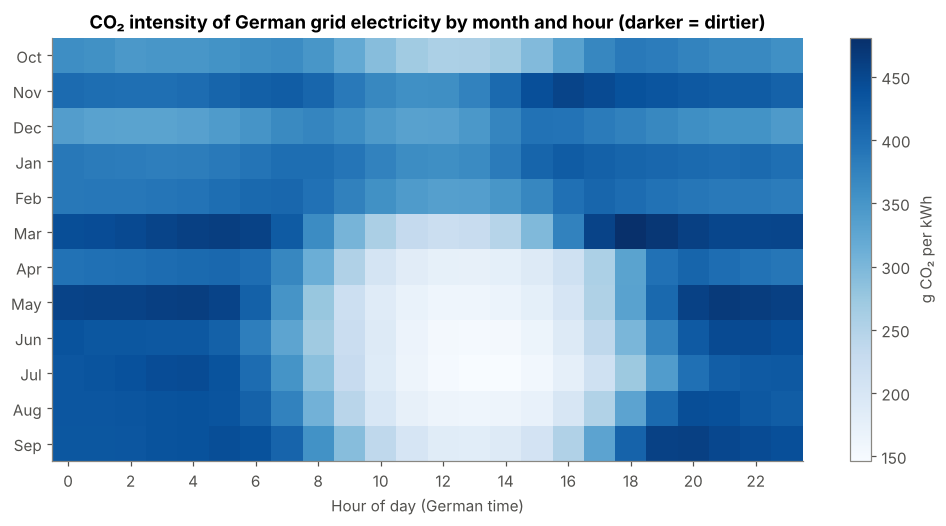

In [3]:
heat = grid.pivot_table(index="month", columns="hour", values="co2_g_per_kwh", aggfunc="mean")
order = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
heat = heat.reindex(order)
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_yticks(range(12)); ax.set_yticklabels(pd.to_datetime([f"2026-{m:02d}-01" for m in order]).strftime("%b"))
ax.grid(False)
fig.colorbar(im, ax=ax).set_label("g CO₂ per kWh")
ax.set(title="CO₂ intensity of German grid electricity by month and hour (darker = dirtier)",
       xlabel="Hour of day (German time)")
save(fig, "W5_A_co2_heatmap")
plt.show()

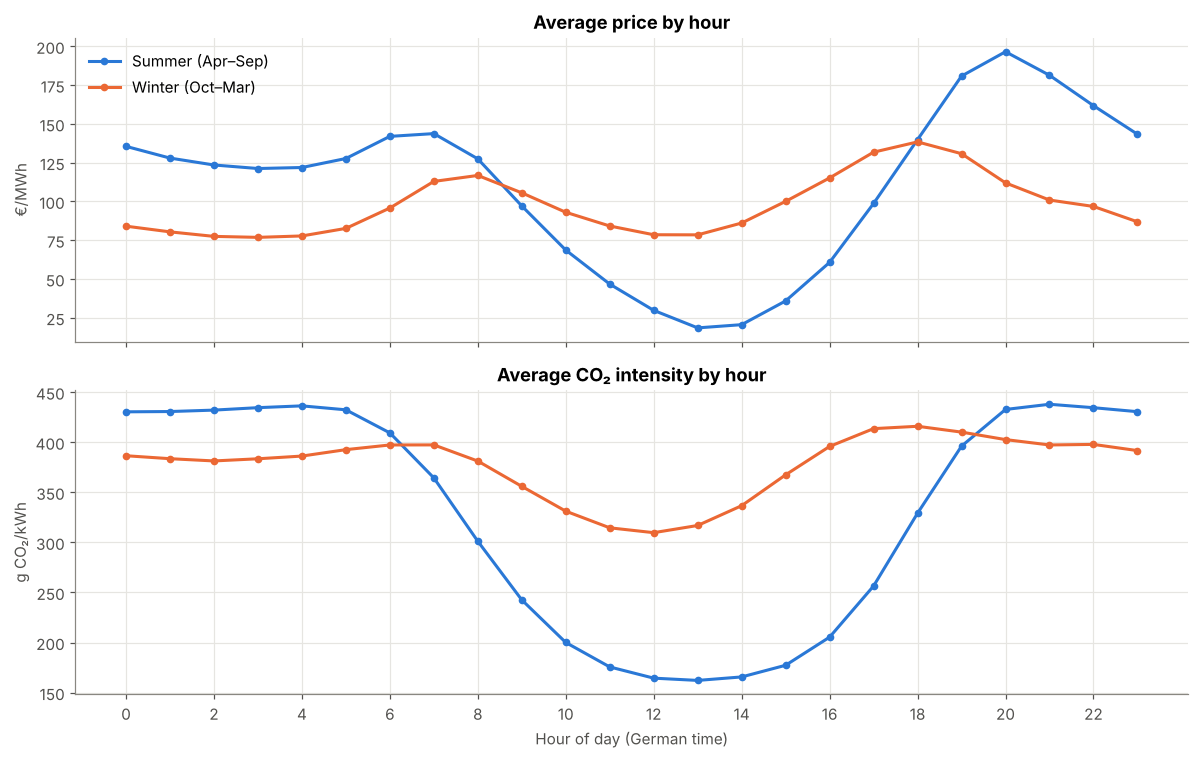

Correlation price vs. CO₂ per quarter-hour: 0.70 (whole year), 0.76 (summer)


In [4]:
prof = grid.groupby(["season", "hour"])[["price_eur_mwh", "co2_g_per_kwh"]].mean().reset_index()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for i, (season, g) in enumerate(prof.groupby("season")):
    ax1.plot(g["hour"], g["price_eur_mwh"], color=COLORS[i], marker="o", markersize=4, label=season)
    ax2.plot(g["hour"], g["co2_g_per_kwh"], color=COLORS[i], marker="o", markersize=4, label=season)
ax1.set(title="Average price by hour", ylabel="€/MWh")
ax2.set(title="Average CO₂ intensity by hour", ylabel="g CO₂/kWh", xlabel="Hour of day (German time)",
        xticks=range(0, 24, 2))
ax1.legend(frameon=False, loc="upper left")
fig.tight_layout()
save(fig, "W5_A2_price_vs_co2_by_hour")
plt.show()

r = grid["price_eur_mwh"].corr(grid["co2_g_per_kwh"])
r_summer = grid.loc[grid["season"].str.startswith("Summer"), ["price_eur_mwh", "co2_g_per_kwh"]].corr().iloc[0, 1]
print(f"Correlation price vs. CO₂ per quarter-hour: {r:.2f} (whole year), {r_summer:.2f} (summer)")

**Interpretation**

German grid electricity caused 353 g CO₂ per kWh on average, but it varies a lot: from 86 g in the cleanest quarter-hour to 706 g in the dirtiest. The cleanest hours are around midday from April to August, when the grid goes down to about 150 to 200 g/kWh because of solar. The dirtiest hours are the evenings and nights, especially in March, May and September (around 450 to 480 g/kWh), and in November already in the late afternoon. In winter the pattern is much flatter: there is only a small midday dip to about 310 g/kWh.

And yes, the cheap hours are also the clean hours. The correlation between price and CO₂ is 0.70 over the whole year and 0.76 in summer. In summer, the price at 13:00 is only about 18 €/MWh with about 160 g/kWh, while at night it is around 125 €/MWh with about 430 g/kWh. I think the reason is that both depend on the same thing: when there is a lot of solar and wind, the expensive coal and gas plants are not needed, so the price and the emissions go down together. In the evening the sun goes down and those plants have to start again, so both go up.

---
## Part B · The workshop's emissions and the action plan

In [5]:
tables = results.build_tables(loads, prices, generation)
kpi = tables["kpis"].iloc[0]
machines = tables["machines"].set_index("machine")

print(f"Workshop emissions today: {kpi['baseline_co2_t']:.1f} t CO₂ per year "
      f"({1000 * kpi['baseline_co2_t'] / kpi['energy_mwh']:.0f} g per kWh used)")
standby_co2 = (machines["standby_mwh"] / machines["energy_mwh"] * machines["co2_t"]).sum()
print(f"Of which roughly from standby: {standby_co2:.1f} t")
machines[["type", "energy_mwh", "co2_t", "cost_eur"]].sort_values("co2_t", ascending=False).round(1)

  2026-03: trained on 137 days, tested on 31 days


  2026-04: trained on 168 days, tested on 30 days


  2026-05: trained on 198 days, tested on 31 days


  2026-06: trained on 229 days, tested on 30 days


  2026-07: trained on 259 days, tested on 31 days


  2026-08: trained on 290 days, tested on 31 days


  2026-09: trained on 321 days, tested on 30 days


Workshop emissions today: 34.4 t CO₂ per year (342 g per kWh used)
Of which roughly from standby: 16.6 t


,type,energy_mwh,co2_t,cost_eur
machine,,,,
DNG 50 evo (mill),cycling,42.1,14.8,4405.4
JWA 24 (liquid cooler),cycling,19.1,6.3,2013.1
MV 2400 R (wire EDM),continuous,11.4,3.9,1254.0
CF ST 161 (water chiller),cycling,9.4,3.3,939.3
DMU 125 (5-axis mill),shift-bound,6.2,2.1,668.9
Chiron 800 (5-axis mill),shift-bound,6.0,2.1,649.4
CTX 800 TC (lathe-mill),shift-bound,2.6,0.9,291.4
E110 (lathe),shift-bound,2.4,0.7,227.9
E30 D2 (lathe),shift-bound,0.6,0.2,64.9


In [6]:
lev = tables["levers"].set_index("lever")
show = lev[lev["status"] != "theoretical"][["saving_eur", "co2_saved_t", "status"]]
show["co2_saved_%"] = 100 * show["co2_saved_t"] / kpi["baseline_co2_t"]
show.round(1)

,saving_eur,co2_saved_t,status,co2_saved_%
lever,,,,
1. Standby off outside working hours,2960.3,10.5,recommended,30.4
2. Summer schedule: Apr-Sep shift +4 h,337.4,0.8,recommended,2.4
3. Weekly shift plan with forecast,364.6,0.9,alternative to 2,2.6


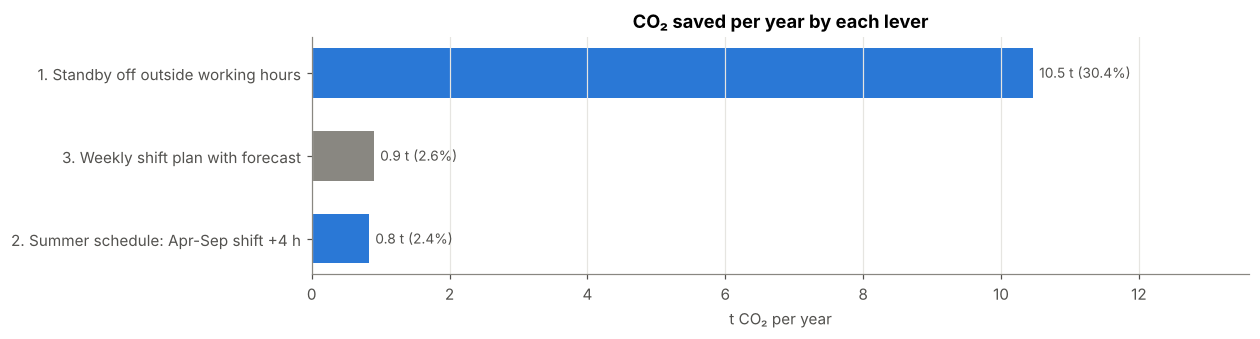

In [7]:
s = show["co2_saved_t"].sort_values()
fig, ax = plt.subplots(figsize=(11, 2.8))
colors = [COLORS[0] if lev.loc[n, "status"] == "recommended" else "#898781" for n in s.index]
ax.barh(s.index, s.values, color=colors, height=0.6)
for y, (n, v) in enumerate(s.items()):
    ax.annotate(f"{v:.1f} t ({100 * v / kpi['baseline_co2_t']:.1f}%)", xy=(v, y), xytext=(4, 0),
                textcoords="offset points", va="center", color="#52514e", fontsize=9)
ax.set(title="CO₂ saved per year by each lever", xlabel="t CO₂ per year", xlim=(0, s.max() * 1.3))
ax.grid(axis="y", visible=False)
save(fig, "W5_B_co2_by_lever")
plt.show()

**Interpretation**

Switching standby off saves 10.5 t CO₂ per year, which is 30% of the workshop's emissions. The summer schedule saves only 0.8 t (2.4%) and the weekly forecast plan 0.9 t (2.6%).

The difference is big because the two levers work in a different way. Switching standby off removes energy completely: about 28 MWh per year that is simply not used any more, so it causes no emissions at all. The summer schedule uses exactly the same amount of energy, it only moves part of it to cleaner hours. And the part that moves is small: only the movable machines, only on weekdays from April to September, and only the hours that change. So it can only save the difference between a dirtier and a cleaner hour on a small amount of energy. Both levers are good for the climate, but using less energy has a much bigger effect than using it at a better time.

---
## Part C · Final results of the project

In [8]:
final = pd.Series({
    "Electricity cost today (wholesale)": euro(kpi["baseline_cost_eur"]),
    "Energy per year": f"{kpi['energy_mwh']:.0f} MWh",
    "Price paid vs. market average": f"{kpi['price_paid_eur_mwh']:.1f} vs. {kpi['market_avg_eur_mwh']:.1f} €/MWh",
    "Standby share of energy": f"{kpi['standby_share_pct']:.0f}% ({euro(kpi['standby_cost_eur'])} per year)",
    "Theoretical shifting upper bound": euro(kpi["upper_bound_shift_eur"]),
    "Lever 1 – standby off": euro(kpi["lever1_standby_off_eur"]),
    "Lever 2 – summer schedule +4 h": euro(kpi["lever2_summer_shift_eur"]),
    "Recommended saving (1 + 2)": f"{euro(kpi['recommended_saving_eur'])} per year = {kpi['recommended_saving_pct']:.0f}% of the bill",
    "CO₂ today": f"{kpi['baseline_co2_t']:.1f} t per year",
    "CO₂ saved (1 + 2)": f"{kpi['recommended_co2_saved_t']:.1f} t per year = {kpi['recommended_co2_saved_pct']:.0f}%",
}, name="Result")
final.to_frame()

,Result
Electricity cost today (wholesale),"€10,573"
Energy per year,100 MWh
Price paid vs. market average,105.3 vs. 104.0 €/MWh
Standby share of energy,"48% (€5,072 per year)"
Theoretical shifting upper bound,"€2,157"
Lever 1 – standby off,"€2,960"
Lever 2 – summer schedule +4 h,€337
Recommended saving (1 + 2),"€3,298 per year = 31% of the bill"
CO₂ today,34.4 t per year
CO₂ saved (1 + 2),11.3 t per year = 33%


In [9]:
results.export(tables)          # writes dashboard/data/*.csv for Streamlit and Power BI

Saved 8 tables -> /tmp/real/dashboard/data


**Interpretation**

The workshop pays about €10,600 per year for electricity and causes 34 t of CO₂, and almost half of that energy is used while nothing is produced. My recommendation is to first switch off the standby of the DNG 50 evo and the JWA 24 cooler at night and on the weekend (after checking with the operators), and then to start the shift about 4 hours later in summer. Together this saves about €3,300 per year (31% of the bill) and 11 t of CO₂ (33%). Because cheap hours are also clean hours, saving money and saving CO₂ go in the same direction here, so there is no trade-off between the two.

---
## Key findings

1. German grid electricity is cleanest around midday from April to August (about 150 to 200 g CO₂/kWh) and dirtiest in the evenings and at night (up to about 480 g/kWh on average), with an average of 353 g/kWh over the year.
2. Cheap hours are clean hours: price and CO₂ intensity have a correlation of 0.70 (0.76 in summer), because solar and wind push both down at the same time.
3. The workshop causes about 34 t of CO₂ per year, and almost half of it (17 t) comes from standby, mainly from the DNG 50 evo.
4. The action plan saves about 11 t of CO₂ per year (33%) on top of €3,300. Almost all of it (10.5 t) comes from switching standby off, the summer schedule adds 0.8 t.
5. Using less energy has a much bigger climate effect than using it at better times, and for this workshop saving money and saving CO₂ point in the same direction.

## Next step
Look at the results in the dashboards: `streamlit run dashboard/app.py` and Power BI (`docs/POWERBI_GUIDE.md`).